# Regularisation with Lasso and Ridge regression

## The formulas for the cost function

### Unregularised regression

$$
\text{Cost} =
\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

### L1 Regularisation (Lasso)

$$
\text{Cost} =
\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\lambda\sum_{j=1}^{m}|w_j|
$$

### L2 Regularisation (Ridge)

$$
\text{Cost} =
\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+
\lambda\sum_{j=1}^{m}w_j^2
$$

Where:

- $n$: number of observations.
- $y_i$: actual value for observation $i$.
- $\hat{y}_i$: predicted value for observation $i$.
- $m$: number of coefficients.
- $w_j$: coefficient of feature $j$.
- $\lambda \geq 0$: regularisation strength. Larger values apply a stronger penalty.

## Code from ChatGPT

- **`n_samples = 100`**: Generates 100 observations. With a 40% test split, 60 are used for training and 40 for testing.
- **`n_features = 80`**: Generates 80 input features per observation. Only the first two contribute to the target; the remaining 78 are irrelevant.

There is no requirement for `n_samples` to exceed `n_features`. This example deliberately has more features than training observations, making unregularised regression prone to overfitting and illustrating how Ridge and Lasso can improve generalisation.

In this Python code, `alpha` plays the role of $\lambda$: it controls regularisation strength. The exact numerical correspondence depends on how the library scales the objective, so the diagram’s lambda values should not be assumed identical to scikit-learn’s alpha values.

Cost should be minimised. The model seeks coefficients that make this quantity as small as possible:

$$\text{Cost}=\text{MSE}+\lambda\times\text{penalty}$$

It balances:
- **Low MSE**: accurate predictions.
- **Low penalty**: smaller coefficients.

With a fixed $\lambda$, the model may accept a slightly higher MSE if smaller coefficients reduce the total cost.

In the `GridSearchCV`, the **negative MSE score is maximised**, which is equivalent to minimising MSE.

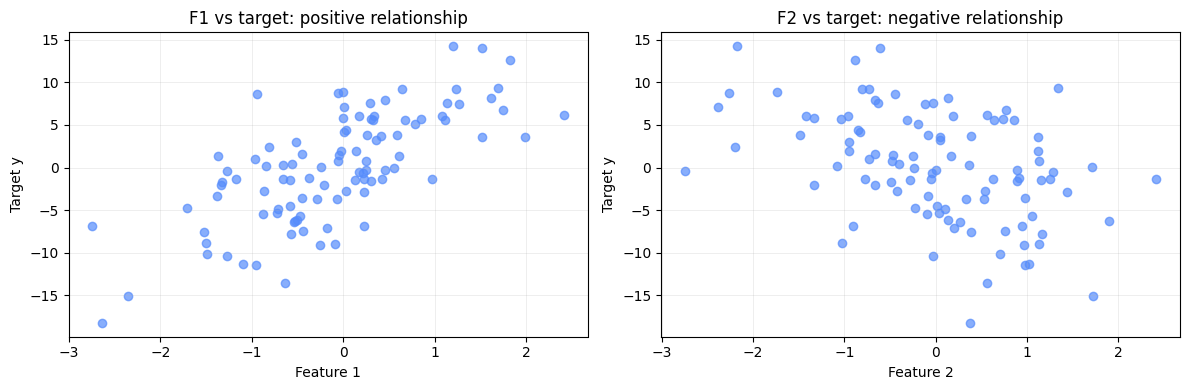

Model                   Train MSE   Test MSE  Zero coefs
No regularisation            0.00      50.87           0
Lasso (L1)                   8.74      11.71          59
Ridge (L2)                   1.48      35.02           0


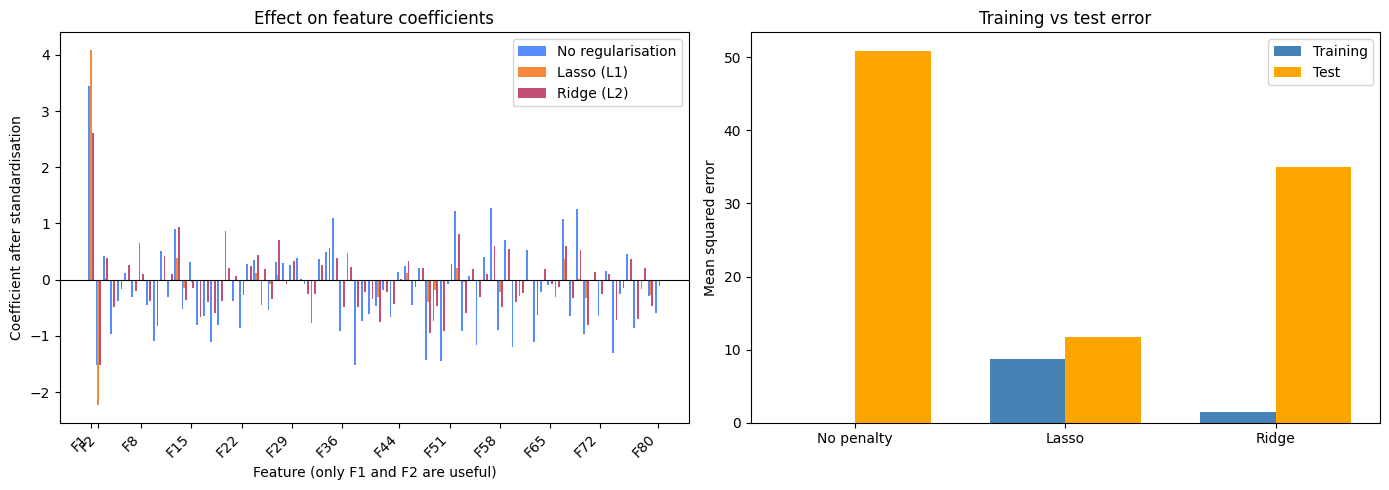

In [32]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Reproducible data
rng = np.random.default_rng(seed=42)

n_samples = 100
n_features = 80 # if n_samples == 10, use n_features = 10
X = rng.normal(size=(n_samples, n_features))

if n_features == 10:
    # When using n_features = 10
    # Only the first two features affect the target
    true_coefficients = np.array([5, -3, 0, 0, 0, 0, 0, 0, 0, 0])
else:
    true_coefficients = np.zeros(n_features)
    true_coefficients[:2] = [5, -3]

y = X @ true_coefficients + rng.normal(scale=3, size=n_samples)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.4,    # 40% for testing; 60% for training
    random_state=42  # Makes the split reproducible
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, ax in enumerate(axes):
    ax.scatter(X[:, i], y, alpha=0.7)
    ax.set_xlabel(f"Feature {i + 1}")
    ax.set_ylabel("Target y")
    ax.grid(alpha=0.3)

axes[0].set_title("F1 vs target: positive relationship")
axes[1].set_title("F2 vs target: negative relationship")

plt.tight_layout()
plt.show()


def plot_lasso_and_ridge(l1_alpha, l2_alpha):
    # Standardisation makes the penalty comparable across features.
    # The scaler learns its settings from the training data only.
    models = {
        "No regularisation": make_pipeline(
            StandardScaler(), LinearRegression()
        ),
        "Lasso (L1)": make_pipeline(
            StandardScaler(), Lasso(alpha=l1_alpha, max_iter=10000)
        ),
        "Ridge (L2)": make_pipeline(
            StandardScaler(), Ridge(alpha=l2_alpha)
        ),
    }

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    positions = np.arange(n_features)
    bar_width = 0.25

    print(f"{'Model':<22} {'Train MSE':>10} {'Test MSE':>10} {'Zero coefs':>11}")

    for i, (name, model) in enumerate(models.items()):
        model.fit(X_train, y_train)

        train_mse = mean_squared_error(y_train, model.predict(X_train))
        test_mse = mean_squared_error(y_test, model.predict(X_test))

        # Coefficients describe a one-standard-deviation feature increase
        coefficients = model.steps[-1][1].coef_
        zero_count = np.count_nonzero(np.abs(coefficients) < 1e-10)

        print(
            f"{name:<22} {train_mse:>10.2f} "
            f"{test_mse:>10.2f} {zero_count:>11}"
        )

        axes[0].bar(
            positions + (i - 1) * bar_width,
            coefficients,
            width=bar_width,
            label=name,
        )

        axes[1].bar(
            i - 0.18, train_mse, width=0.36,
            color="steelblue", label="Training" if i == 0 else None
        )
        axes[1].bar(
            i + 0.18, test_mse, width=0.36,
            color="orange", label="Test" if i == 0 else None
        )

    axes[0].axhline(0, color="black", linewidth=0.8)

    feature_count = len(positions)

    if feature_count < 11:
        # Show all positions.
        axes[0].set_xticks(positions)
        axes[0].set_xticklabels([f"F{i + 1}" for i in positions])
    else:
        # Show at most 12 evenly spaced labels, plus the two useful features
        tick_positions = np.unique(
            np.concatenate([
                np.arange(min(2, feature_count)),
                np.linspace(
                    0,
                    feature_count - 1,
                    num=min(12, feature_count),
                    dtype=int,
                ),
            ])
        )

        axes[0].set_xticks(tick_positions)
        axes[0].set_xticklabels(
            [f"F{i + 1}" for i in tick_positions],
            rotation=45,
            ha="right",
        )

    axes[0].set_xlabel("Feature (only F1 and F2 are useful)")
    axes[0].set_ylabel("Coefficient after standardisation")
    axes[0].set_title("Effect on feature coefficients")
    axes[0].legend()

    axes[1].set_xticks(range(len(models)))
    axes[1].set_xticklabels(["No penalty", "Lasso", "Ridge"])
    axes[1].set_ylabel("Mean squared error")
    axes[1].set_title("Training vs test error")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_lasso_and_ridge(l1_alpha=0.5, l2_alpha=10)

### Selecting regularisation strength with cross-validation

This cell searches for suitable values of **alpha**, the regularisation strength, for Ridge (L2) and Lasso (L1).

- **Ridge** shrinks coefficients towards zero, usually keeping all features.
- **Lasso** can set coefficients to exactly zero, effectively selecting features.
- Larger alpha values apply stronger regularisation. Too much regularisation can cause underfitting.

### Scaling the features

Each model uses a pipeline containing `StandardScaler` followed by the regression model.

Scaling makes the regularisation penalty comparable across features with different units or scales. Keeping the scaler inside the pipeline ensures it learns its settings only from the fitting data within each cross-validation round, preventing validation-data leakage.

### Searching for alpha

`GridSearchCV` evaluates 100 logarithmically spaced alpha values for each model:

| Model | Parameter | Search range | Number of values |
|---|---|---|---:|
| Ridge | `ridge__alpha` | 0.0001 to 1,000 | 100 |
| Lasso | `lasso__alpha` | 0.0001 to 100 | 100 |

The double underscore in each parameter name connects the pipeline step to its parameter. For example, `ridge__alpha` refers to the `alpha` parameter of the `ridge` step.

The alpha values for Ridge and Lasso are not directly comparable because the models use different penalty definitions.

### Five-fold cross-validation

With `cv=5`, each search divides the training data into five folds. For every alpha:

1. Fit the pipeline using four folds.
2. Evaluate it on the remaining fold.
3. Repeat until every fold has been used for validation.
4. Average the five validation scores.

Each search performs **100 × 5 = 500 fits**, followed by one final fit of the winning pipeline on all the training data.

For these regression models, `cv=5` uses folds without shuffling by default.

### Evaluation metric

`scoring="neg_mean_squared_error"` uses negative MSE because `GridSearchCV` always selects the highest score.

For example, a score of −10 is better than −20 because it corresponds to a lower MSE.

Negating `best_score_` converts the selected model's average validation score back into a positive MSE.

### Reported results

| Output | Meaning |
|---|---|
| Best alpha | Alpha with the lowest average validation MSE among the values tested |
| Cross-validation MSE | Average validation MSE for the selected alpha |
| Test MSE | MSE on the separate test set after tuning |
| Features retained | Number of nonzero coefficients in the selected Lasso model |

`best_params_` contains the selected alpha. `best_estimator_` contains the winning pipeline, refitted on all the training data.

For Lasso, `max_iter=100000` sets the maximum number of optimisation iterations allowed per fit. It does not control the number of alpha values tested.

### Plotting the selected models

The final call to `plot_lasso_and_ridge` passes the selected alpha values to the plotting function. It refits the models and compares:

- Their feature coefficients.
- Their training and test MSE.

### Interpretation

A higher training MSE combined with a lower test MSE can indicate that regularisation has reduced overfitting.

The selected alpha is the best found within the tested grid according to cross-validation; it is not a universal optimum. If the selected value lies at an endpoint of the search range, consider extending that range.

The test set is used only for final evaluation. Repeatedly changing the modelling approach based on its results can make it less reliable as an independent assessment.

Ridge parameters:
 - Best alpha: 27.8256
 - Cross-validation MSE: 32.41
 - Test MSE: 32.03
Lasso parameters:
 - Best alpha: 1.1498
 - Cross-validation MSE: 17.23
 - Test MSE: 12.15
 - Features retained: 2 / 80
Model                   Train MSE   Test MSE  Zero coefs
No regularisation            0.00      50.87           0
Lasso (L1)                  14.97      12.15          78
Ridge (L2)                   4.20      32.03           0


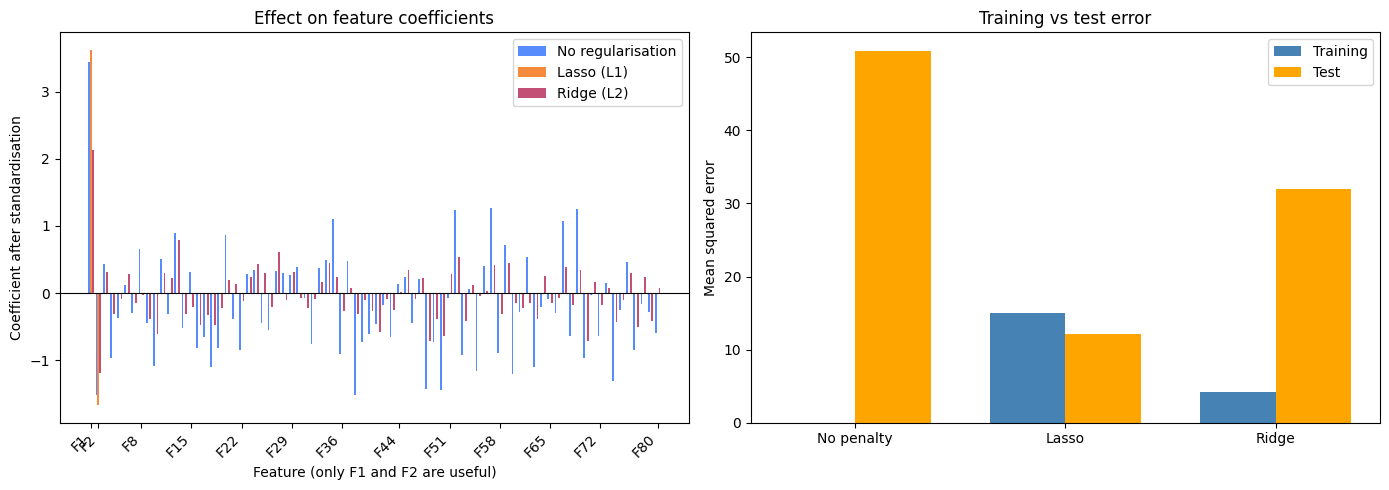

In [33]:
from sklearn.model_selection import GridSearchCV

# Keep scaling inside the pipeline to avoid validation-data leakage
ridge_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), Ridge()),
    param_grid={
        "ridge__alpha": np.logspace(-4, 3, 100)
    },
    scoring="neg_mean_squared_error",
    cv=5
)

ridge_search.fit(X_train, y_train)

best_alpha_ridge = ridge_search.best_params_['ridge__alpha']

print("Ridge parameters:")
print(f" - Best alpha: {best_alpha_ridge:.4f}")
print(
    f" - Cross-validation MSE: {-ridge_search.best_score_:.2f}"
)
print(
    f" - Test MSE: "
    f"{mean_squared_error(y_test, ridge_search.predict(X_test)):.2f}"
)

lasso_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Lasso(max_iter=100000)
    ),
    param_grid={
        "lasso__alpha": np.logspace(-4, 2, 100)
    },
    scoring="neg_mean_squared_error",
    cv=5
)

lasso_search.fit(X_train, y_train)

best_alpha_lasso = lasso_search.best_params_["lasso__alpha"]
test_predictions = lasso_search.predict(X_test)
coefficients = lasso_search.best_estimator_.named_steps["lasso"].coef_

print("Lasso parameters:")
print(f" - Best alpha: {best_alpha_lasso:.4f}")
print(f" - Cross-validation MSE: {-lasso_search.best_score_:.2f}")
print(f" - Test MSE: {mean_squared_error(y_test, test_predictions):.2f}")
print(f" - Features retained: {np.count_nonzero(coefficients)} / {X_train.shape[1]}")

plot_lasso_and_ridge(l1_alpha=best_alpha_lasso, l2_alpha=best_alpha_ridge)

### Regularisation results

| Model | Best alpha | Training MSE | Cross-validation MSE | Test MSE | Features retained |
|---|---:|---:|---:|---:|---:|
| No regularisation | — | 0.00 | — | 50.87 | 80 / 80 |
| Lasso (L1) | 1.1498 | 14.97 | 17.23 | 12.15 | 2 / 80 |
| Ridge (L2) | 27.8256 | 4.20 | 32.41 | 32.03 | 80 / 80 |

### Interpretation

- **No regularisation:** Near-zero training error but high test error indicates overfitting.
- **Ridge:** Shrinking coefficients reduces test MSE from 50.87 to 32.03.
- **Lasso:** Setting 78 coefficients to zero gives the lowest test MSE, 12.15. This suits a dataset constructed with only two useful features.

**Key takeaway:** Accepting higher training error can improve generalisation. The best alpha values were selected using cross-validation on the training data.